In [1]:
import numpy as np

import matplotlib.pyplot as plt


def plot_quarter_circle_samples(
    n_left=500,
    n_right=500,
    seed=42,
):
    rng = np.random.default_rng(seed)

    # Use the same random number generator for both figures
    points_left = rng.uniform(0, 1, size=(n_left, 2))
    points_right = rng.uniform(0, 1, size=(n_right, 2))

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    theta = np.linspace(0, np.pi / 2, 300)
    circle_x = np.cos(theta)
    circle_y = np.sin(theta)

    for ax, points, title, markers in [
        (
            axes[0],
            points_left,
            f"Left: {n_left} points",
            {"inside": "o", "outside": "s"},
        ),
        (
            axes[1],
            points_right,
            f"Right: {n_right} points",
            {"inside": "^", "outside": "D"},
        ),
    ]:
        inside = points[:, 0] ** 2 + points[:, 1] ** 2 <= 1
        outside = ~inside

        ax.plot(circle_x, circle_y, color="black", linewidth=2)
        ax.fill_between(circle_x, circle_y, color="lightgray", alpha=0.25)

        ax.scatter(
            points[inside, 0],
            points[inside, 1],
            color="orange",
            marker=markers["inside"],
            label="Inside circle",
            alpha=0.75,
        )

        ax.scatter(
            points[outside, 0],
            points[outside, 1],
            color="blue",
            marker=markers["outside"],
            label="Outside circle",
            alpha=0.75,
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

    return points_left, points_right


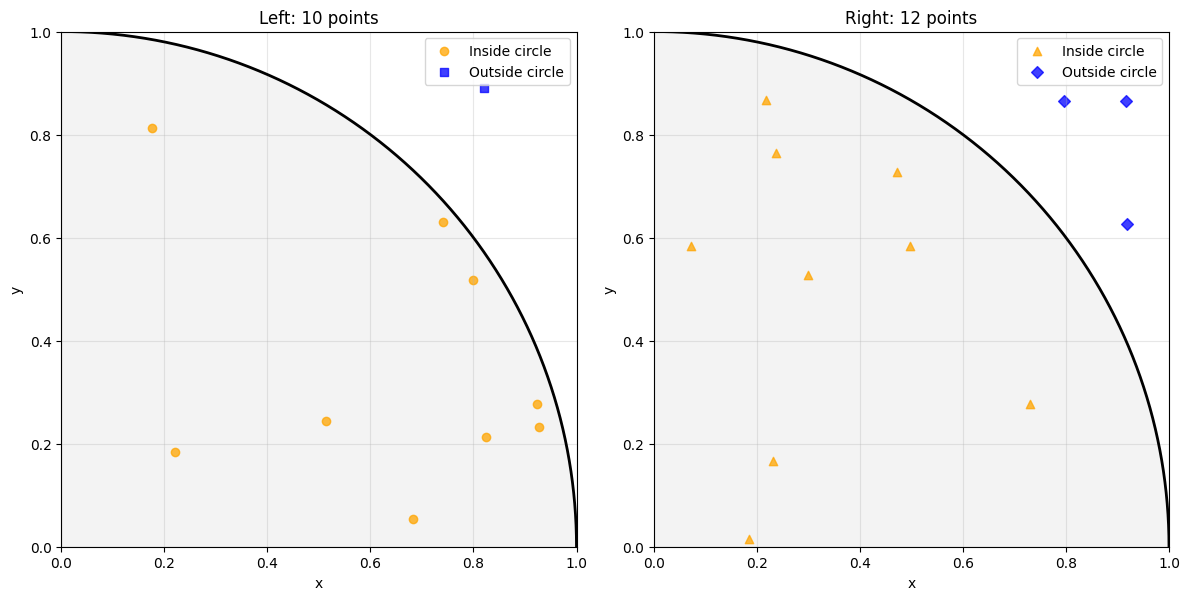

In [3]:

n_left = 10
n_right = 12

points_left, points_right = plot_quarter_circle_samples(
    n_left=n_left,
    n_right=n_right,
    seed=123,
)

In [4]:


inside_left = np.sum(points_left[:, 0] ** 2 + points_left[:, 1] ** 2 <= 1)
inside_right = np.sum(points_right[:, 0] ** 2 + points_right[:, 1] ** 2 <= 1)

area_left = inside_left / n_left
area_right = inside_right / n_right

print(f"Left: {inside_left}/{n_left} points inside → Area approximation: {area_left:.4f}")
print(f"Right: {inside_right}/{n_right} points inside → Area approximation: {area_right:.4f}")

Left: 9/10 points inside → Area approximation: 0.9000
Right: 9/12 points inside → Area approximation: 0.7500


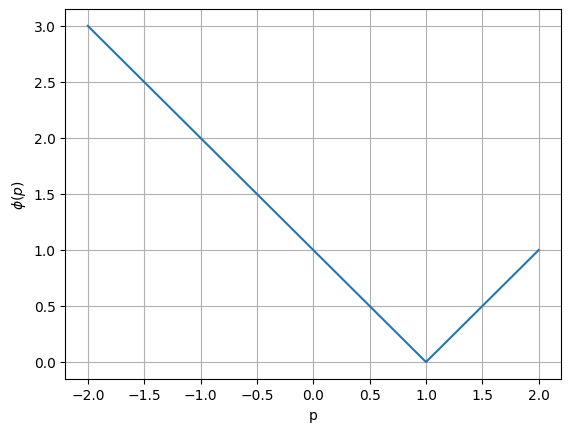

In [7]:
def phi(p):
    return abs(p - 1)

plt.plot(x, phi(x))
plt.xlabel("p")
plt.ylabel(r"$\phi(p)$")
plt.grid(True)
plt.show()

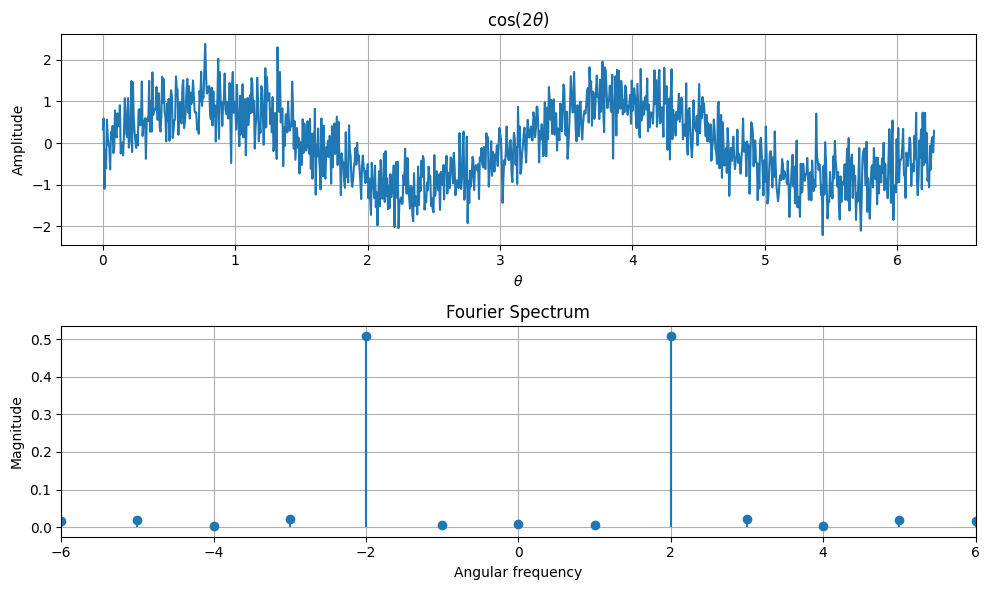

In [10]:
theta = np.linspace(0, 2 * np.pi, 1024, endpoint=False)
# signal plus noise
signal = np.sin(2 * theta) + 0.5 * np.random.normal(size=theta.shape)

spectrum = np.fft.fftshift(np.fft.fft(signal)) / len(signal)
angular_frequency = np.fft.fftshift(
    np.fft.fftfreq(len(theta), d=theta[1] - theta[0])
) * 2 * np.pi

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].plot(theta, signal)
axes[0].set_title(r"$\cos(2\theta)$")
axes[0].set_xlabel(r"$\theta$")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(angular_frequency, np.abs(spectrum), basefmt=" ")
axes[1].set_xlim(-6, 6)
axes[1].set_title("Fourier Spectrum")
axes[1].set_xlabel("Angular frequency")
axes[1].set_ylabel("Magnitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

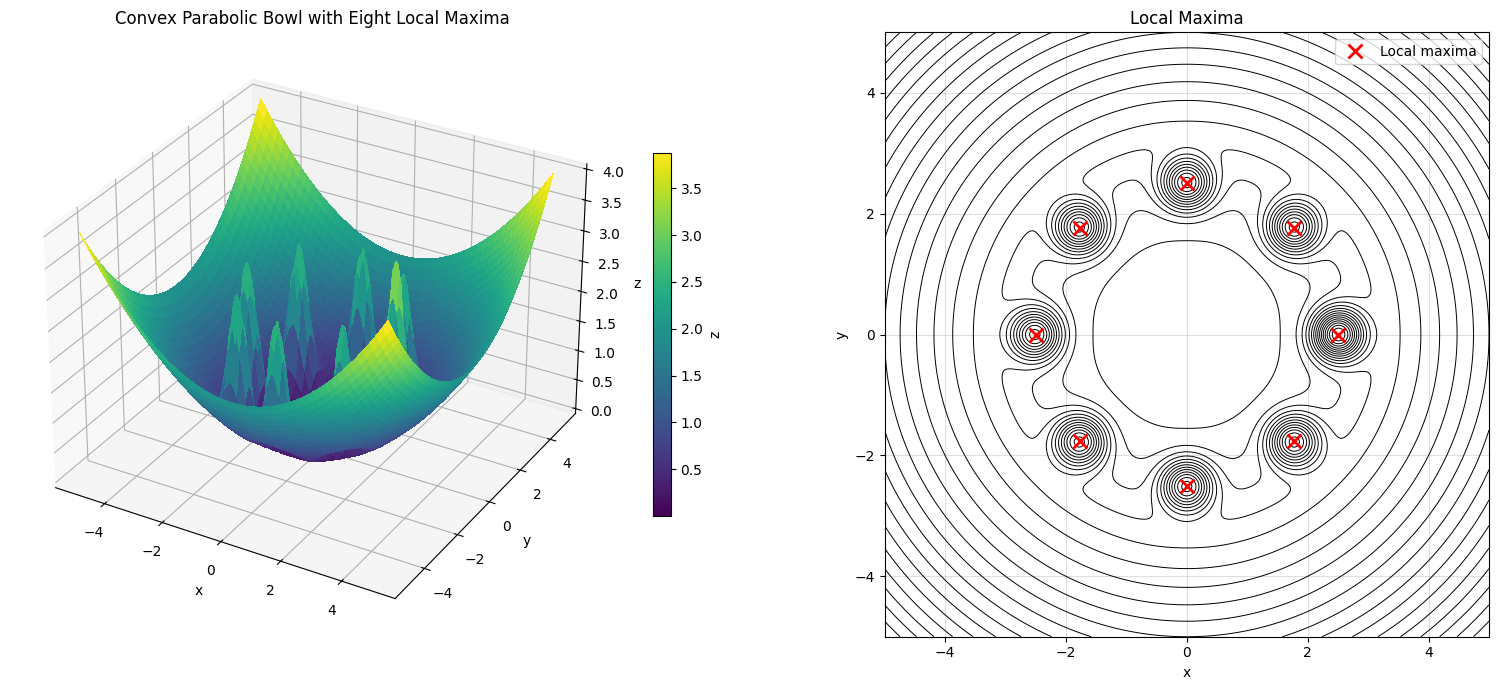

In [24]:
# Create a convex parabolic bowl with eight localized maxima
x = np.linspace(-5, 5, 250)
y = np.linspace(-5, 5, 250)
X, Y = np.meshgrid(x, y)

Z = 0.08 * (X**2 + Y**2)

# Eight Gaussian peaks arranged around the bowl
radius = 2.5
peak_height = 2.2  # controls the height of the eight local maxima above the bowl
peak_heights = [2.9, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2]
peak_width = 0.28

peak_centers = []
for k, angle in enumerate(np.linspace(0, 2 * np.pi, 8, endpoint=False)):
    x0 = radius * np.cos(angle)
    y0 = radius * np.sin(angle)
    peak_centers.append((x0, y0))
    Z += peak_heights[k] * np.exp(
        -((X - x0) ** 2 + (Y - y0) ** 2) / (2 * peak_width**2)
    )

peak_centers = np.array(peak_centers)
peak_z = 0.08 * (peak_centers[:, 0] ** 2 + peak_centers[:, 1] ** 2) + peak_height

# Combined figure: 3D surface + 2D contour projection, side by side
fig = plt.figure(figsize=(16, 7))

# 3D surface plot
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
surface = ax1.plot_surface(
    X,
    Y,
    Z,
    cmap="viridis",
    linewidth=0,
    antialiased=False,
)
ax1.set_title("Convex Parabolic Bowl with Eight Local Maxima")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
fig.colorbar(surface, ax=ax1, shrink=0.6, label="z")

# 2D contour projection (black lines only)
ax2 = fig.add_subplot(1, 2, 2)
ax2.contour(X, Y, Z, levels=20, colors="black", linewidths=0.7)
ax2.plot(
    peak_centers[:, 0],
    peak_centers[:, 1],
    "x",
    color="red",
    markersize=10,
    markeredgewidth=2,
    label="Local maxima",
)
ax2.set_title("Local Maxima")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_aspect("equal")
ax2.grid(True, alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()